# Background evolution: thesis figures

**Purpose:** compare the recorded background level, spread, upper tail, and recurrent structure.
The defaults analyse Fireball IV HRM6 OD1 and BTV 660524 OD0. Add Fireball II HRM3 when its file is ready.

Run from top to bottom in SWAN. Edit the single settings cell first. The original datasets are read only.
This notebook produces descriptive measurements; it does not identify radiation damage, select an optimal
threshold, or establish the benefit of subtraction on beam images.

The main comparison uses threshold-free quantities. The optional excess-pixel and recurrence measurements
have explicit, configurable thresholds. Unknown acquisition metadata stay labelled **missing**.

In [1]:
from pathlib import Path
from collections import Counter
import json
import gc

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pyarrow.dataset as ds
from IPython.display import display

plt.rcParams.update({
    "font.size": 9, "axes.titlesize": 9, "axes.labelsize": 9,
    "legend.fontsize": 8, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.spines.top": False, "axes.spines.right": False,
    "savefig.dpi": 300, "pdf.fonttype": 42,
})
BLUE, ORANGE, PURPLE = "#0072B2", "#D55E00", "#7A5195"

## 1. Settings

Each case is one camera, filter, time interval, and optionally selected exposure/gain/screen/shape.
The default shape choices reproduce the principal groups already inspected. Set `shape=None` to read
all shapes; the code keeps them in separate groups. Logged exposure, gain, and screen changes also split
groups automatically. Missing metadata cannot establish matched settings.

All times are Geneva local time. Start is included; end is excluded. Use `None` for an unrestricted side.
The disabled HRM3 entry needs its actual parquet path before it can run. HRM5 exposure conditions can be
added as separate cases after the metadata/time selection is verified.

In [2]:
CASES = [
    dict(
        enabled=True, key="HRM6_OD1", label="HRM6", campaign="Fireball IV",
        parquet="/eos/user/v/vtsoukni/SWAN_projects/MY HRMT64 image analysis/Fireball_IV/HRM6/HRM6_merged.parquet",
        filter="OD1", start=None, end=None, shape=(850, 700),
        exposure_us=None, gain=None, screen=None,
        dimension_order="height_width", raw_thresholds=[12, 30],
    ),
    dict(
        enabled=True, key="BTV_660524_OD0", label="BTV 660524", campaign="Fireball IV",
        parquet="/eos/user/v/vtsoukni/SWAN_projects/MY HRMT64 image analysis/Fireball_IV/BTV/TT66.BTV.660524_merged.parquet",
        filter="OD0", start=None, end=None, shape=(903, 525),
        exposure_us=None, gain=None, screen=None,
        dimension_order="height_width", raw_thresholds=[20, 30],
        exclude_tail99_above_ADU=4.0,  # exclude only when Q99 - image median > 4 ADU
    ),
    dict(
        enabled=True, key="HRM3_OD1", label="HRM3", campaign="Fireball II",
        parquet="/eos/user/v/vtsoukni/SWAN_projects/MY HRMT64 image analysis/Fireball_2/HRM3/HRM3_merged.parquet",
        filter="OD1", start=None, end=None, shape=(781, 1065),
        exposure_us=None, gain=None, screen=None,
        dimension_order="height_width", raw_thresholds=[12, 30],
        exclude_mean_and_median_above_ADU=150.0,  # both must exceed 150 ADU
    ),
]

LOCAL_TIMEZONE = "Europe/Zurich"
TIMESTAMP_COLUMN = "cycleStampGlob"
TIMESTAMP_UNIT = "ns"
BCT_COLUMNS = [
    "TT60.BCTFI.610225:TOTAL_INTENSITY",
    "TT66.BCTFI.660298:TOTAL_INTENSITY",
]
BATCH_SIZE = 2

# Threshold-independent quantities remain the primary comparison.
EXCESS_DELTA_ADU = 5.0       # supplementary rule: raw pixel > its image median + delta
PERSISTENCE_FRACTION = 0.90  # recurrence in each early/late sample, not a defect diagnosis
N_EPOCH_IMAGES = 50         # first N and last N, disjoint; equal counts within each group
MIN_EPOCH_IMAGES = 5        # otherwise skip the early/late maps for that group

# Raw and median-centred histograms retain all observations in their denominators.
RAW_HIST_EDGES = np.arange(-0.5, 151.5, 1.0)
CENTRED_HIST_EDGES = np.arange(-20.5, 151.5, 1.0)
MAP_DISPLAY_PERCENTILE = 99.5  # display limits only; arrays remain unchanged
MAKE_RECURRENCE_MAPS = True
MAKE_APPENDIX_PLOTS = True   # zero fraction and absolute-cutoff plots

SAVE_RESULTS = True
OUTPUT_DIR = Path("background_evolution_thesis_figures")

## 2. Definitions

For every raw beam-off image $B_t$ with $P$ finite pixels:

- Background selection: **both BCT totals equal zero**.
- Level: $m_t=\mathrm{median}_p B_t(p)$ and $\bar B_t=P^{-1}\sum_p B_t(p)$, in ADU.
- Spatial spread: $s_t=[P^{-1}\sum_p(B_t(p)-\bar B_t)^2]^{1/2}$. This is not temporal read noise.
- Upper-tail excess: $w_q(t)=Q_q(B_t)-m_t$, for $q=99,99.9$.
- Zero fraction: $P^{-1}\sum_p\mathbf1[B_t(p)=0]$.
- Absolute-cutoff fraction: $f_T(t)=P^{-1}\sum_p\mathbf1[B_t(p)>T]$.
- Excess fraction: $r_\Delta(t)=P^{-1}\sum_p\mathbf1[B_t(p)>m_t+\Delta]$.

The level records uniform shifts; the excess quantities intentionally remove a uniform shift.
They must be interpreted together. This is centring for characterisation, not background subtraction.
ADU values are not calibrated electron counts or a camera-independent measure of sensor quality.

The configured $\Delta=5$ ADU is an operational amplitude cutoff, not a significance level or an
optimised threshold. A 5-versus-10 ADU comparison must use the same accepted images and early/late
samples; the threshold-free level and percentile excess do not depend on this choice.

Early/late samples use the first/last accepted images in time, with equal non-overlapping sample counts.
Their **pixel-wise medians** are distinct from the median of an image-level statistic.
At a fixed coordinate, recurrence is the fraction of those images passing $B_t(p)>m_t+\Delta$.
The recurrence mask requires this fraction to be at least the configured persistence fraction.
These masks use a different rule from the older raw-value percentile or median-reference masks.

In [3]:
def geneva_time(value):
    if value is None:
        return None
    value = pd.Timestamp(value)
    return value.tz_localize(LOCAL_TIMEZONE) if value.tzinfo is None else value.tz_convert(LOCAL_TIMEZONE)

def metadata_text(value):
    if value is None or pd.isna(value):
        return "missing"
    return str(value)

def image_from_row(elements, dimensions, case):
    dimensions = tuple(int(x) for x in dimensions)
    if len(dimensions) != 2 or min(dimensions) <= 0:
        raise ValueError("Invalid image dimensions")
    order = case["dimension_order"]
    if order not in ("height_width", "width_height"):
        raise ValueError("Unknown dimension order")
    shape = dimensions if order == "height_width" else dimensions[::-1]
    image = np.asarray(elements, dtype=np.float32).reshape(shape)
    if not np.isfinite(image).all():
        raise ValueError("Nonfinite pixel values")
    return image

def background_batches(case, columns):
    dataset = ds.dataset(case["parquet"], format="parquet")
    no_beam = (ds.field(BCT_COLUMNS[0]) == 0) & (ds.field(BCT_COLUMNS[1]) == 0)
    return dataset.scanner(
        columns=columns, filter=no_beam, batch_size=BATCH_SIZE, use_threads=False,
    ).to_batches()

def scan_case(case):
    dataset = ds.dataset(case["parquet"], format="parquet")
    required = BCT_COLUMNS + [TIMESTAMP_COLUMN, "filter", "image_elements", "image_dimensions"]
    missing = set(required) - set(dataset.schema.names)
    if missing:
        raise KeyError(f"{case['key']}: required columns absent: {sorted(missing)}")
    metadata_columns = [x for x in ("camera_exposure_time_us", "camera_gain", "screen") if x in dataset.schema.names]
    for field, column in [("exposure_us", "camera_exposure_time_us"), ("gain", "camera_gain"), ("screen", "screen")]:
        if case[field] is not None and column not in metadata_columns:
            raise KeyError(f"{case['key']}: cannot enforce {column}; it is not logged")
    start, end = geneva_time(case["start"]), geneva_time(case["end"])
    if start is not None and end is not None and end <= start:
        raise ValueError("End must follow start")
    print(f"Reading {case['campaign']} / {case['label']} / {case['filter']}")
    print("Available exposure/gain/screen columns:", metadata_columns or "none")
    records, rejected, excluded_records = [], Counter(), []
    offset = 0
    columns = list(dict.fromkeys(required + metadata_columns))
    for batch in background_batches(case, columns):
        frame = batch.to_pandas()
        times = frame[TIMESTAMP_COLUMN]
        if pd.api.types.is_numeric_dtype(times):
            times = pd.to_datetime(times, unit=TIMESTAMP_UNIT, utc=True, errors="coerce")
        else:
            times = pd.to_datetime(times, utc=True, errors="coerce")
        times = times.dt.tz_convert(LOCAL_TIMEZONE)
        for i, row in frame.iterrows():
            timestamp = times.iloc[i]
            if pd.isna(timestamp):
                rejected["invalid_timestamp"] += 1
                continue
            if (start is not None and timestamp < start) or (end is not None and timestamp >= end):
                rejected["outside_time_window"] += 1
                continue
            if str(row["filter"]).strip().upper() != case["filter"].strip().upper():
                rejected["other_filter"] += 1
                continue
            if any(case[field] is not None and row[column] != case[field] for field, column in [
                ("exposure_us", "camera_exposure_time_us"), ("gain", "camera_gain"), ("screen", "screen")
            ]):
                rejected["other_configuration"] += 1
                continue
            try:
                image = image_from_row(row["image_elements"], row["image_dimensions"], case)
            except (TypeError, ValueError):
                rejected["invalid_image"] += 1
                continue
            if case["shape"] is not None and image.shape != tuple(case["shape"]):
                rejected["other_shape"] += 1
                continue
            exposure = metadata_text(row.get("camera_exposure_time_us"))
            gain = metadata_text(row.get("camera_gain"))
            screen = metadata_text(row.get("screen"))
            configuration = f"shape={image.shape}; exposure_us={exposure}; gain={gain}; screen={screen}"
            values = image.ravel()
            q50, q95, q99, q999 = np.percentile(values, [50, 95, 99, 99.9])
            record = dict(
                case=case["key"], configuration=configuration, timestamp=timestamp,
                day=timestamp.strftime("%Y-%m-%d"), row_index=offset+i,
                height=image.shape[0], width=image.shape[1], pixels=values.size,
                exposure_us=exposure, gain=gain, screen=screen,
                median=q50, mean=np.mean(values, dtype=np.float64), std=np.std(values, dtype=np.float64),
                q95=q95, q99=q99, q999=q999, tail99=q99-q50, tail999=q999-q50,
                zero_fraction=np.mean(values == 0), excess_fraction=np.mean(values > q50+EXCESS_DELTA_ADU),
                minimum=values.min(), maximum=values.max(),
            )
            # Apply the requested image cuts before any downstream analysis or sample selection.
            exclusion_reasons = []
            level_cut = case.get("exclude_mean_and_median_above_ADU")
            if level_cut is not None and record["mean"] > level_cut and record["median"] > level_cut:
                exclusion_reasons.append(f"mean_and_median_gt_{level_cut:g}_ADU")
            tail_cut = case.get("exclude_tail99_above_ADU")
            if tail_cut is not None and record["tail99"] > tail_cut:
                exclusion_reasons.append(f"tail99_gt_{tail_cut:g}_ADU")
            if exclusion_reasons:
                for reason in exclusion_reasons:
                    rejected[reason] += 1
                excluded = {name: record[name] for name in ("case", "row_index", "timestamp", "mean", "median", "tail99")}
                excluded["reason"] = "; ".join(exclusion_reasons)
                excluded_records.append(excluded)
                continue
            for threshold in case["raw_thresholds"]:
                record[f"fraction_gt_{threshold:g}"] = np.mean(values > threshold)
            records.append(record)
        offset += len(frame)
    print("Accepted:", len(records), "; rejected:", dict(rejected))
    if not records:
        raise RuntimeError(f"No backgrounds accepted for {case['key']}")
    result = pd.DataFrame(records).sort_values(["configuration", "timestamp", "row_index"]).reset_index(drop=True)
    group_map = {config: f"{case['key']}_g{i:02d}" for i, config in enumerate(sorted(result.configuration.unique()), 1)}
    result["group"] = result.configuration.map(group_map)
    return result, excluded_records

def export_figure(fig, stem):
    if SAVE_RESULTS:
        fig.savefig(OUTPUT_DIR / f"{stem}.pdf", bbox_inches="tight")
        fig.savefig(OUTPUT_DIR / f"{stem}.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

def time_axis(ax, series):
    if series.nunique() == 1:
        centre = series.iloc[0]
        ax.set_xlim(centre-pd.Timedelta(minutes=15), centre+pd.Timedelta(minutes=15))
    locator = mdates.AutoDateLocator(minticks=3, maxticks=4)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator, tz=LOCAL_TIMEZONE))
    ax.tick_params(axis="x", which="both", labelbottom=True)
    ax.xaxis.get_offset_text().set_visible(True)
    ax.set_xlabel("Geneva local time")
    ax.grid(alpha=0.18)

def add_y_headroom(ax, fraction=0.08):
    """Leave space above every plotted series, including axes sharing this y scale."""
    arrays = [np.asarray(line.get_ydata(), dtype=float).ravel()
              for sibling in ax.get_shared_y_axes().get_siblings(ax) for line in sibling.lines]
    if not arrays:
        return
    values = np.concatenate(arrays)
    values = values[np.isfinite(values)]
    if not values.size:
        return
    bottom = ax.get_ylim()[0]
    peak = float(values.max())
    if ax.get_yscale() == "log":
        if peak <= 0 or bottom <= 0:
            return
        top = peak * 10**(fraction * max(np.log10(peak / bottom), 1.0))
    else:
        top = peak + fraction * max(peak - bottom, 1.0)
    ax.set_ylim(top=top)

def points(ax, frame, column, color, label):
    ax.plot(frame.timestamp, frame[column], ".", color=color, markersize=2.5, alpha=0.55, label=label)

## 3. Scan the enabled cases and check the inventory

The requested brightness cuts are applied before the inventory, all statistics, every plot, and
early/late selection: **HRM3: exclude an image if both mean > 150 ADU and median > 150 ADU;
BTV: exclude an image if $Q_{99}-m>4$ ADU.** Equality at either cutoff is retained. HRM6 is unchanged.
The printed rejected counts and separate exclusion log document this restricted analysis subset;
a brightness cut alone does not establish that a rejected image is invalid.

Missing files or required columns stop the run rather than silently dropping a requested dataset.
Missing optional metadata is visible in the inventory. The group identifiers below are reused
in every filename and summary table.

In [4]:
active_cases = [case for case in CASES if case["enabled"]]
if not active_cases or len({c["key"] for c in active_cases}) != len(active_cases):
    raise ValueError("Enable at least one case and use unique case keys")
if not 0 < PERSISTENCE_FRACTION <= 1 or EXCESS_DELTA_ADU < 0:
    raise ValueError("Check the recurrence fraction and excess delta")
if MIN_EPOCH_IMAGES < 1 or N_EPOCH_IMAGES < MIN_EPOCH_IMAGES:
    raise ValueError("Check the early/late sample sizes")
for case in active_cases:
    if not Path(case["parquet"]).exists():
        raise FileNotFoundError(case["parquet"])
if SAVE_RESULTS:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
case_lookup = {case["key"]: case for case in active_cases}
scanned_cases = [scan_case(case) for case in active_cases]
measurements = pd.concat([accepted for accepted, excluded in scanned_cases], ignore_index=True)
# Audit only: excluded rows never enter measurements or any plot/sample below.
excluded_backgrounds = pd.DataFrame(
    [row for accepted, excluded in scanned_cases for row in excluded],
    columns=["case", "row_index", "timestamp", "mean", "median", "tail99", "reason"],
)
group_order = []
group_lookup = {}
for case in active_cases:
    for group, frame in measurements.loc[measurements.case == case["key"]].groupby("group", sort=True):
        group_order.append(group)
        group_lookup[group] = dict(case=case, title=f"{case['campaign']} — {case['label']} ({case['filter']})", frame=frame)

inventory = measurements.groupby(["group", "case", "configuration"], sort=False).agg(
    backgrounds=("row_index", "size"), first=("timestamp", "min"), last=("timestamp", "max"),
    median_level=("median", "median"), median_mean=("mean", "median"),
    median_spatial_std=("std", "median"), median_tail99=("tail99", "median"),
).reset_index()
with pd.option_context("display.max_colwidth", None):
    display(inventory)

metrics = ["median", "mean", "std", "tail99", "tail999", "zero_fraction", "excess_fraction"]
daily_rows = []
for (group, day), frame in measurements.groupby(["group", "day"], sort=False):
    row = dict(group=group, day=day, backgrounds=len(frame))
    for metric in metrics:
        row[f"{metric}_median"] = frame[metric].median()
        row[f"{metric}_q10"] = frame[metric].quantile(0.10)
        row[f"{metric}_q90"] = frame[metric].quantile(0.90)
    daily_rows.append(row)
daily_summary = pd.DataFrame(daily_rows)
display(daily_summary[["group", "day", "backgrounds", "median_median", "std_median", "tail99_median"]])
if SAVE_RESULTS:
    excluded_backgrounds.to_csv(OUTPUT_DIR / "excluded_backgrounds.csv", index=False)
    measurements.to_csv(OUTPUT_DIR / "background_measurements.csv", index=False)
    inventory.to_csv(OUTPUT_DIR / "dataset_inventory.csv", index=False)
    daily_summary.to_csv(OUTPUT_DIR / "daily_summary.csv", index=False)

Reading Fireball IV / HRM6 / OD1
Available exposure/gain/screen columns: none
Accepted: 877 ; rejected: {'other_filter': 968, 'other_shape': 104, 'invalid_image': 7}
Reading Fireball IV / BTV 660524 / OD0
Available exposure/gain/screen columns: none
Accepted: 1926 ; rejected: {'invalid_image': 24, 'tail99_gt_4_ADU': 1}
Reading Fireball II / HRM3 / OD1
Available exposure/gain/screen columns: none
Accepted: 1285 ; rejected: {'other_filter': 1130, 'invalid_image': 50, 'mean_and_median_gt_150_ADU': 3, 'other_shape': 293}


,group,case,configuration,backgrounds,first,last,median_level,median_mean,median_spatial_std,median_tail99
0,HRM6_OD1_g01,HRM6_OD1,"shape=(850, 700); exposure_us=missing; gain=missing; screen=missing",877,2026-06-10 21:02:36.135000064+02:00,2026-06-13 16:46:16.935000064+02:00,1.0,8.122392,56.357407,101.0
1,BTV_660524_OD0_g01,BTV_660524_OD0,"shape=(903, 525); exposure_us=missing; gain=missing; screen=missing",1926,2026-06-08 17:07:33.735000064+02:00,2026-06-13 16:46:16.935000064+02:00,17.0,16.960324,1.120262,2.0
2,HRM3_OD1_g01,HRM3_OD1,"shape=(781, 1065); exposure_us=missing; gain=missing; screen=missing",1285,2024-04-29 14:34:10.935000064+02:00,2024-05-02 20:03:34.935000064+02:00,0.0,0.660196,4.534885,14.0


,group,day,backgrounds,median_median,std_median,tail99_median
0,HRM6_OD1_g01,2026-06-10,141,1.0,38.616997,27.0
1,HRM6_OD1_g01,2026-06-11,204,1.0,44.507890,46.0
2,HRM6_OD1_g01,2026-06-12,342,1.0,66.204574,166.5
3,HRM6_OD1_g01,2026-06-13,190,2.0,68.764620,221.0
4,BTV_660524_OD0_g01,2026-06-08,348,17.0,1.082319,2.0
5,BTV_660524_OD0_g01,2026-06-09,466,17.0,1.089563,2.0
6,BTV_660524_OD0_g01,2026-06-10,180,17.0,1.356856,2.0
7,BTV_660524_OD0_g01,2026-06-11,203,17.0,1.113779,2.0
8,BTV_660524_OD0_g01,2026-06-12,422,17.0,1.134138,2.0
9,BTV_660524_OD0_g01,2026-06-13,307,17.0,1.122813,2.0


## 4. Main thesis comparison: level and upper tail

Each row is one configuration. Left: mean and median of individual images. Right: $Q_{99}-m$.
Each column uses a common vertical range within a page, so differences in recorded ADU are visible.
The local-detail figures in the next cell resolve smaller changes. No time points are connected across gaps.

Cases in the same campaign use the same calendar interval. Different campaigns retain their own dates;
they are not aligned in irradiation time or accumulated dose. A page contains at most three groups.

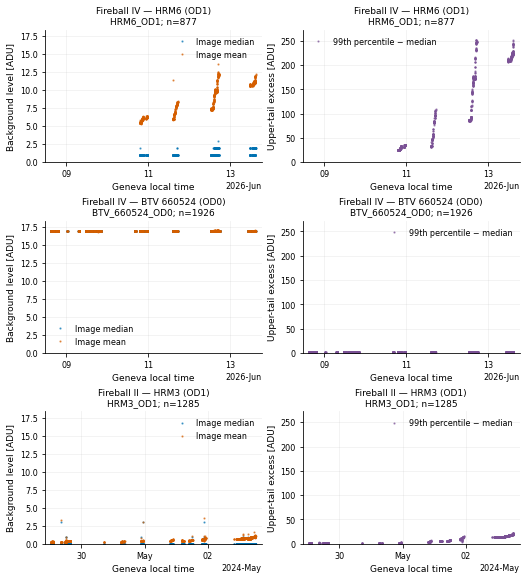

In [5]:
campaign_windows = {}
for group in group_order:
    item = group_lookup[group]
    campaign = item["case"]["campaign"]
    a, b = item["frame"].timestamp.min(), item["frame"].timestamp.max()
    old = campaign_windows.get(campaign, (a, b))
    campaign_windows[campaign] = (min(a, old[0]), max(b, old[1]))

for page_start in range(0, len(group_order), 3):
    page = group_order[page_start:page_start+3]
    fig, axes = plt.subplots(len(page), 2, figsize=(7.2, 2.65*len(page)), sharey="col", squeeze=False, constrained_layout=True)
    for row_number, group in enumerate(page):
        item = group_lookup[group]
        frame = item["frame"]
        points(axes[row_number, 0], frame, "median", BLUE, "Image median")
        points(axes[row_number, 0], frame, "mean", ORANGE, "Image mean")
        points(axes[row_number, 1], frame, "tail99", PURPLE, "99th percentile − median")
        for column in range(2):
            ax = axes[row_number, column]
            ax.set_title(f"{item['title']}\n{group.removesuffix('_g01')}; n={len(frame)}")
            time_axis(ax, frame.timestamp)
            a, b = campaign_windows[item["case"]["campaign"]]
            pad = max((b-a)*0.03, pd.Timedelta(minutes=15))
            ax.set_xlim(a-pad, b+pad)
            ax.legend(loc="best", frameon=False)
        axes[row_number, 0].set_ylabel("Background level [ADU]")
        axes[row_number, 1].set_ylabel("Upper-tail excess [ADU]")
    # Set common limits only after every row has been plotted.
    # Setting limits earlier would disable autoscaling before a later case is added.
    level_min = min(0.0, min(float(group_lookup[g]["frame"][["median", "mean"]].min().min()) for g in page))
    level_max = max(float(group_lookup[g]["frame"][["median", "mean"]].max().max()) for g in page)
    tail_max = max(float(group_lookup[g]["frame"].tail99.max()) for g in page)
    axes[0, 0].set_ylim(level_min, max(level_max + 0.08*(level_max-level_min), level_min+1))
    axes[0, 1].set_ylim(0, max(tail_max*1.08, 1))
    export_figure(fig, f"01_level_and_tail_comparison_page_{page_start//3+1}")

## 5. Detail for each case

These figures use each case's own vertical ranges, with all accepted images included.
They show level, spatial standard deviation, percentile excess, and the optional excess fraction.
The last panel measures shape above the image median; interpret it alongside the level panel.

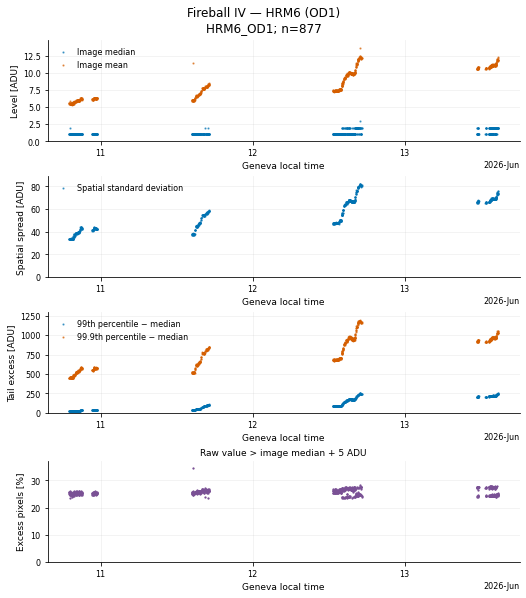

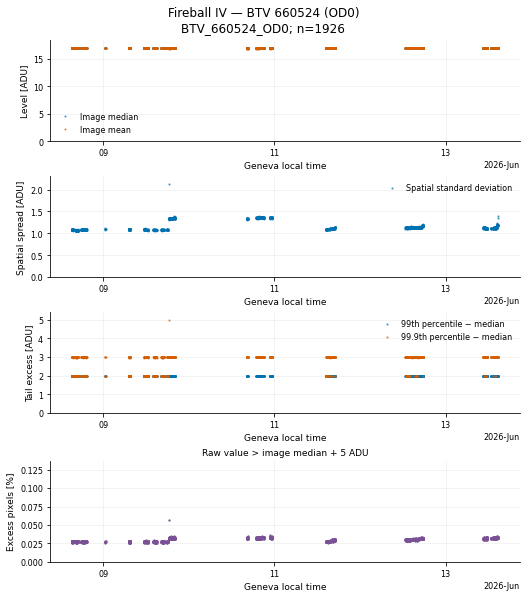

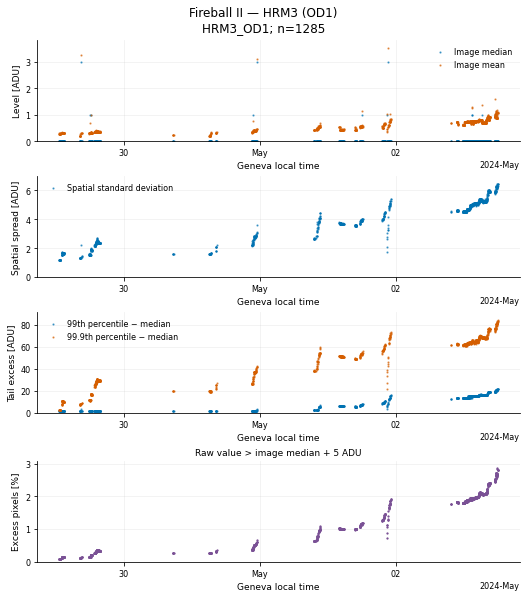

In [6]:
for group in group_order:
    item = group_lookup[group]
    frame = item["frame"]
    fig, axes = plt.subplots(4, 1, figsize=(7.2, 8.2), sharex=True, constrained_layout=True)
    points(axes[0], frame, "median", BLUE, "Image median")
    points(axes[0], frame, "mean", ORANGE, "Image mean")
    axes[0].set_ylabel("Level [ADU]")
    points(axes[1], frame, "std", BLUE, "Spatial standard deviation")
    axes[1].set_ylabel("Spatial spread [ADU]")
    points(axes[2], frame, "tail99", BLUE, "99th percentile − median")
    points(axes[2], frame, "tail999", ORANGE, "99.9th percentile − median")
    axes[2].set_ylabel("Tail excess [ADU]")
    axes[3].plot(frame.timestamp, 100*frame.excess_fraction, ".", color=PURPLE, markersize=2.5)
    axes[3].set_ylabel("Excess pixels [%]")
    axes[3].set_title(f"Raw value > image median + {EXCESS_DELTA_ADU:g} ADU")
    for ax in axes:
        time_axis(ax, frame.timestamp)
        ax.set_ylim(bottom=0)
        add_y_headroom(ax)
    for ax in axes[:3]:
        ax.legend(frameon=False)
    fig.suptitle(f"{item['title']}\n{group.removesuffix('_g01')}; n={len(frame)}")
    export_figure(fig, f"02_detail_{group}")

## 6. Build equal-count early and late background samples

Use $N=\min(N_\mathrm{requested},\lfloor n/2\rfloor)$. Samples never overlap.
Equal counts do not mean equal durations. The output table records their actual dates and times.
The code reloads only these selected rows into one sample stack at a time (about 119 MB for 50 HRM6 images).

Raw histograms use the original values. Centred histograms use each image's own median before pooling.
Histograms use all pixel observations as the denominator, even when the plotted range omits the extremes.
Median images keep floating-point values. Differences and residuals retain their signs.

In [7]:
def load_epoch(case, rows):
    rows = rows.sort_values(["timestamp", "row_index"])
    indices = rows.row_index.astype(int).tolist()
    positions = {index: i for i, index in enumerate(indices)}
    shape = (int(rows.height.iloc[0]), int(rows.width.iloc[0]))
    stack = np.empty((len(rows), *shape), dtype=np.float32)
    found = np.zeros(len(rows), dtype=bool)
    raw_hist = np.zeros(len(RAW_HIST_EDGES)-1, dtype=np.int64)
    centred_hist = np.zeros(len(CENTRED_HIST_EDGES)-1, dtype=np.int64)
    recurrence_counts = np.zeros(shape, dtype=np.uint32)
    offset = 0
    for batch in background_batches(case, ["image_elements", "image_dimensions"]):
        for i in range(batch.num_rows):
            index = offset+i
            if index not in positions:
                continue
            image = image_from_row(batch.column("image_elements")[i].as_py(), batch.column("image_dimensions")[i].as_py(), case)
            if image.shape != shape:
                raise ValueError("Selected sample geometry changed")
            stack[positions[index]] = image
            found[positions[index]] = True
            values = image.ravel()
            median = np.median(values)
            raw_hist += np.histogram(values, bins=RAW_HIST_EDGES)[0]
            centred_hist += np.histogram(values-median, bins=CENTRED_HIST_EDGES)[0]
            recurrence_counts += image > median+EXCESS_DELTA_ADU
        offset += batch.num_rows
        if found.all():
            break
    if not found.all():
        raise RuntimeError("A selected row could not be reloaded; check that the input file is unchanged")
    median_image = np.median(stack, axis=0, overwrite_input=True)
    del stack
    gc.collect()
    recurrence = recurrence_counts.astype(float)/len(rows)
    persistent_mask = recurrence >= PERSISTENCE_FRACTION
    return dict(
        median_image=median_image, raw_hist=raw_hist, centred_hist=centred_hist,
        observations=len(rows)*int(np.prod(shape)), recurrence=recurrence,
        persistent_mask=persistent_mask,
    )

epoch_data, epoch_rows = {}, []
for group in group_order:
    item = group_lookup[group]
    frame = item["frame"].sort_values(["timestamp", "row_index"])
    n = min(N_EPOCH_IMAGES, len(frame)//2)
    if n < MIN_EPOCH_IMAGES:
        print(f"{group}: only {len(frame)} backgrounds; early/late figures skipped")
        continue
    epoch_data[group] = {}
    for name, rows in [("early", frame.head(n)), ("late", frame.tail(n))]:
        epoch = load_epoch(item["case"], rows)
        epoch_data[group][name] = epoch
        summary = dict(
            group=group, epoch=name, backgrounds=n, first=rows.timestamp.min(), last=rows.timestamp.max(),
            median_image_level=float(np.median(epoch["median_image"])),
            recurrent_excess_coordinates=int(epoch["persistent_mask"].sum()),
            recurrent_excess_fraction=float(epoch["persistent_mask"].mean()),
            fraction_outside_raw_histogram=1-epoch["raw_hist"].sum()/epoch["observations"],
            fraction_outside_centred_histogram=1-epoch["centred_hist"].sum()/epoch["observations"],
        )
        for metric in metrics:
            summary[f"median_{metric}"] = rows[metric].median()
        epoch_rows.append(summary)
        if SAVE_RESULTS:
            np.save(OUTPUT_DIR / f"{group}_{name}_median.npy", epoch["median_image"])
            np.save(OUTPUT_DIR / f"{group}_{name}_recurrence.npy", epoch["recurrence"])
            rows[["row_index", "timestamp", "configuration"]].to_csv(OUTPUT_DIR / f"{group}_{name}_selected_rows.csv", index=False)
epoch_summary = pd.DataFrame(epoch_rows)
display(epoch_summary)
if SAVE_RESULTS:
    epoch_summary.to_csv(OUTPUT_DIR / "early_late_summary.csv", index=False)

,group,epoch,backgrounds,first,last,median_image_level,recurrent_excess_coordinates,recurrent_excess_fraction,fraction_outside_raw_histogram,fraction_outside_centred_histogram,median_median,median_mean,median_std,median_tail99,median_tail999,median_zero_fraction,median_excess_fraction
0,HRM6_OD1_g01,early,50,2026-06-10 21:02:36.135000064+02:00,2026-06-10 21:46:45.735000064+02:00,1.0,5838,0.009812,0.003493,0.003476,1.0,5.511650,33.820786,25.0,455.001,0.470771,0.250724
1,HRM6_OD1_g01,late,50,2026-06-13 16:13:04.935000064+02:00,2026-06-13 16:46:16.935000064+02:00,1.0,21295,0.035790,0.014076,0.013968,2.0,11.215757,69.653926,225.0,969.001,0.448055,0.247706
2,BTV_660524_OD0_g01,early,50,2026-06-08 17:07:33.735000064+02:00,2026-06-08 17:27:57.735000064+02:00,17.0,106,0.000224,0.000004,0.000004,17.0,16.958870,1.082899,2.0,2.000,0.000000,0.000275
3,BTV_660524_OD0_g01,late,50,2026-06-13 16:13:04.935000064+02:00,2026-06-13 16:46:16.935000064+02:00,17.0,127,0.000268,0.000006,0.000006,17.0,16.972528,1.174859,2.0,3.000,0.000000,0.000329
4,HRM3_OD1_g01,early,50,2024-04-29 14:34:10.935000064+02:00,2024-04-29 15:11:34.935000064+02:00,0.0,543,0.000653,0.000007,0.000007,0.0,0.306890,1.528732,2.0,8.000,0.757827,0.001161
5,HRM3_OD1_g01,late,50,2024-05-02 19:34:32.535000064+02:00,2024-05-02 20:03:34.935000064+02:00,0.0,16848,0.020256,0.000161,0.000161,0.0,0.964580,6.242669,21.0,81.000,0.699421,0.026527


## 7. Main thesis comparison: early/late distributions

Blue: early sample. Orange: late sample. Each row represents one camera/configuration.
The left column shows the raw distribution; the right removes each image's scalar median.
A narrow non-zero raw peak can therefore be distinguished from an extended tail.
The vertical axes are logarithmic percentages per 1-ADU bin; empty bins are omitted.
Both columns use the same displayed horizontal range (approximately -20 to 100 ADU), including an
empty negative region for non-negative raw data. Histogram bins and all denominators are unchanged.
The same histogram axes are used across rows. These are recorded digital distributions, not calibrated noise spectra.

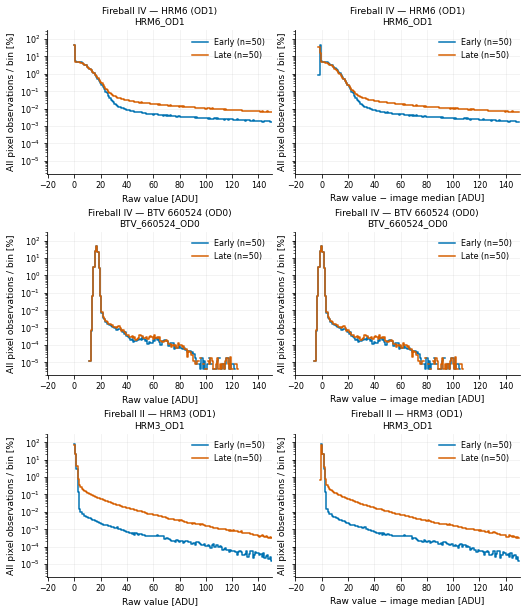

In [8]:
epoch_groups = [group for group in group_order if group in epoch_data]
for page_start in range(0, len(epoch_groups), 3):
    page = epoch_groups[page_start:page_start+3]
    fig, axes = plt.subplots(len(page), 2, figsize=(7.2, 2.8*len(page)), sharex="col", sharey=True, squeeze=False, constrained_layout=True)
    for row_number, group in enumerate(page):
        for name, color in [("early", BLUE), ("late", ORANGE)]:
            epoch = epoch_data[group][name]
            for column, (field, edges) in enumerate([("raw_hist", RAW_HIST_EDGES), ("centred_hist", CENTRED_HIST_EDGES)]):
                percentage = 100*epoch[field]/epoch["observations"]
                centres = (edges[:-1]+edges[1:])/2
                axes[row_number, column].step(centres, np.where(percentage>0, percentage, np.nan), where="mid", color=color, label=f"{name.capitalize()} (n={int(epoch_summary.loc[(epoch_summary.group==group)&(epoch_summary.epoch==name), 'backgrounds'].iloc[0])})")
        for column in range(2):
            ax = axes[row_number, column]
            has_values = any(np.any(epoch_data[group][name]["raw_hist" if column==0 else "centred_hist"]>0) for name in ["early", "late"])
            if has_values:
                ax.set_yscale("log")
            ax.set_title(f"{group_lookup[group]['title']}\n{group.removesuffix('_g01')}")
            ax.set_ylabel("All pixel observations / bin [%]")
            ax.set_xlim(min(RAW_HIST_EDGES[0], CENTRED_HIST_EDGES[0]),
                        max(RAW_HIST_EDGES[-1], CENTRED_HIST_EDGES[-1]))
            ax.tick_params(axis="x", which="both", labelbottom=True)
            ax.set_xlabel("Raw value [ADU]" if column==0 else "Raw value − image median [ADU]")
            ax.grid(alpha=0.18)
            ax.legend(frameon=False)
    add_y_headroom(axes[0, 0])
    export_figure(fig, f"03_early_late_distributions_page_{page_start//3+1}")

## 8. Spatial evolution of the median background

Each figure uses one common raw colour scale for its early and late panels. The difference panel uses
a symmetric scale around zero. Different cameras have independent display limits, printed below.
Percentile limits affect colours only. The NPY arrays keep the complete signed values.
These maps describe a reproducible background estimate; the next cell measures recurrence explicitly.

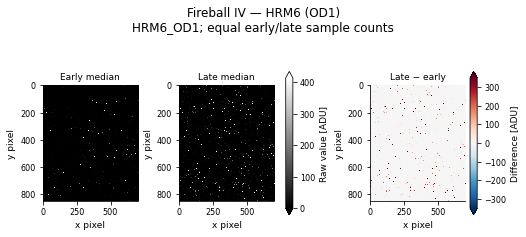

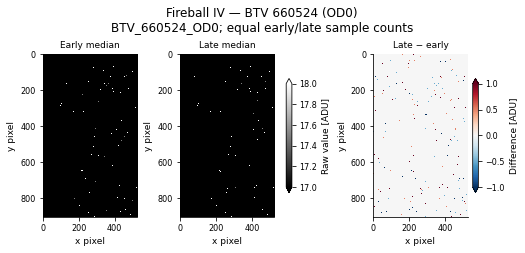

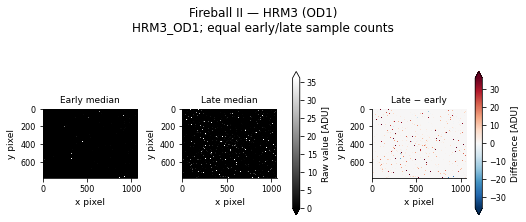

,group,raw_vmin,raw_vmax,difference_limit,actual_difference_min,actual_difference_max
0,HRM6_OD1_g01,0.0,413.0,349.5,-2362.0,4095.0
1,BTV_660524_OD0_g01,17.0,18.0,1.0,-29.5,170.5
2,HRM3_OD1_g01,0.0,36.0,36.0,-265.5,1747.5


In [9]:
map_display_rows = []
for group in epoch_groups:
    early = epoch_data[group]["early"]["median_image"]
    late = epoch_data[group]["late"]["median_image"]
    difference = late-early
    vmin = min(float(np.percentile(early, 1)), float(np.percentile(late, 1)))
    vmax = max(float(np.percentile(early, MAP_DISPLAY_PERCENTILE)), float(np.percentile(late, MAP_DISPLAY_PERCENTILE)))
    vmax = max(vmax, vmin+1)
    limit = max(float(np.percentile(np.abs(difference), MAP_DISPLAY_PERCENTILE)), 1.0)
    fig, axes = plt.subplots(1, 3, figsize=(7.2, 3.4), constrained_layout=True)
    image = axes[0].imshow(early, cmap="gray", origin="upper", interpolation="nearest", vmin=vmin, vmax=vmax)
    axes[1].imshow(late, cmap="gray", origin="upper", interpolation="nearest", vmin=vmin, vmax=vmax)
    diff_image = axes[2].imshow(difference, cmap="RdBu_r", origin="upper", interpolation="nearest", vmin=-limit, vmax=limit)
    for ax, title in zip(axes, ["Early median", "Late median", "Late − early"]):
        ax.set(title=title, xlabel="x pixel", ylabel="y pixel")
    fig.colorbar(image, ax=axes[:2].tolist(), label="Raw value [ADU]", shrink=0.7, extend="both")
    fig.colorbar(diff_image, ax=axes[2], label="Difference [ADU]", shrink=0.7, extend="both")
    fig.suptitle(f"{group_lookup[group]['title']}\n{group.removesuffix('_g01')}; equal early/late sample counts")
    export_figure(fig, f"04_median_maps_{group}")
    map_display_rows.append(dict(group=group, raw_vmin=vmin, raw_vmax=vmax, difference_limit=limit,
                                 actual_difference_min=float(difference.min()), actual_difference_max=float(difference.max())))
map_display_limits = pd.DataFrame(map_display_rows)
display(map_display_limits)
if SAVE_RESULTS:
    map_display_limits.to_csv(OUTPUT_DIR / "map_display_limits.csv", index=False)

## 9. Recurrent excess coordinates (optional output)

White coordinates passed **raw value > image median + delta** in at least the configured fraction of
the early/late backgrounds. Black means that this recurrence requirement was not met.
The count measures recurrence for the chosen sample and rule. It is not a count of proven damaged pixels.
For $N=50$ and 90%, at least 45 occurrences are required.

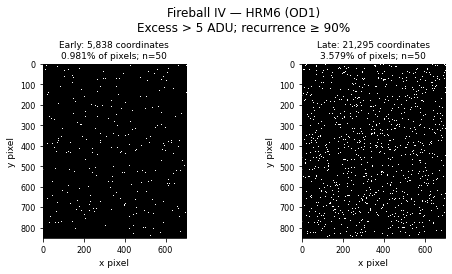

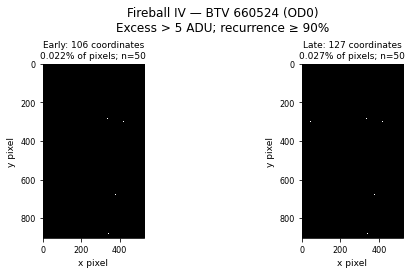

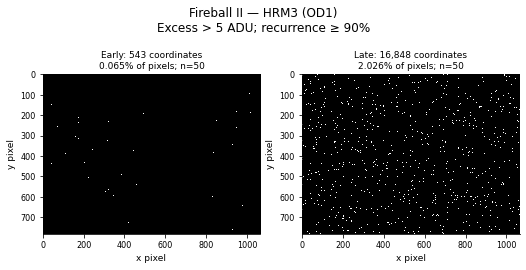

In [10]:
if MAKE_RECURRENCE_MAPS:
    for group in epoch_groups:
        fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.7), constrained_layout=True)
        for ax, name in zip(axes, ["early", "late"]):
            mask = epoch_data[group][name]["persistent_mask"]
            n = int(epoch_summary.loc[(epoch_summary.group==group)&(epoch_summary.epoch==name), "backgrounds"].iloc[0])
            ax.imshow(mask, cmap="gray", vmin=0, vmax=1, origin="upper", interpolation="nearest")
            ax.set_title(f"{name.capitalize()}: {int(mask.sum()):,} coordinates\n{100*mask.mean():.3f}% of pixels; n={n}")
            ax.set(xlabel="x pixel", ylabel="y pixel")
        fig.suptitle(f"{group_lookup[group]['title']}\nExcess > {EXCESS_DELTA_ADU:g} ADU; recurrence ≥ {100*PERSISTENCE_FRACTION:g}%")
        export_figure(fig, f"05_recurrence_maps_{group}")

## 10. Appendix figures and saved settings

The optional appendix figure retains the zero-valued fraction and the original absolute-cutoff fractions.
It uses camera-specific, explicitly labelled raw cutoffs. Fractions with different raw cutoffs should not
be combined into a single purported common bright-pixel count.

Daily 10th–90th ranges in the CSV describe variation between acquired backgrounds, not confidence intervals.
Use the inventory and early/late table for thesis captions, including missing metadata and actual sample dates.
The median samples here diagnose evolution; they do not define an optimal reference for beam subtraction.

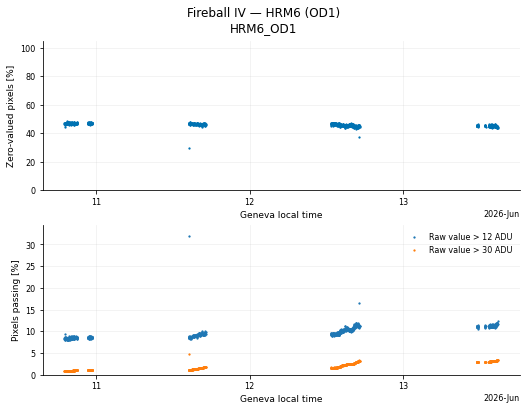

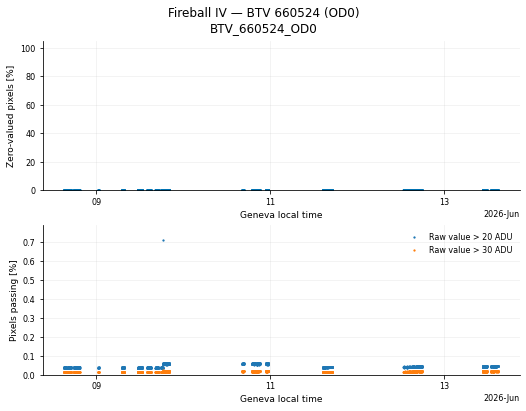

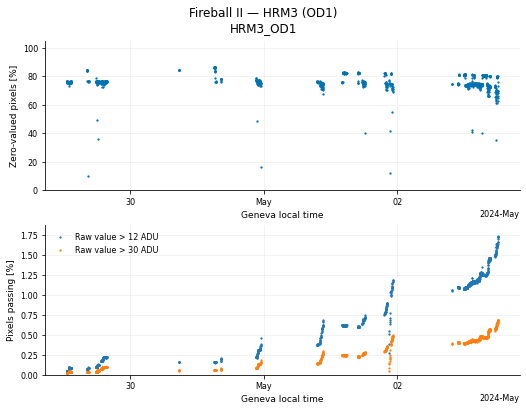

Saved PDF/PNG figures, scalar tables, sample indices, median arrays, and recurrence arrays to: /eos/home-i03/v/vtsoukni/SWAN_projects/MY HRMT64 image analysis/background_evolution_thesis_figures


In [11]:
if MAKE_APPENDIX_PLOTS:
    for group in group_order:
        item = group_lookup[group]
        frame = item["frame"]
        fig, axes = plt.subplots(2, 1, figsize=(7.2, 5.6), sharex=True, constrained_layout=True)
        axes[0].plot(frame.timestamp, 100*frame.zero_fraction, ".", color=BLUE, markersize=2.5)
        axes[0].set(ylabel="Zero-valued pixels [%]", ylim=(0, 105))
        for threshold in item["case"]["raw_thresholds"]:
            axes[1].plot(frame.timestamp, 100*frame[f"fraction_gt_{threshold:g}"], ".", markersize=2.5, label=f"Raw value > {threshold:g} ADU")
        axes[1].set_ylabel("Pixels passing [%]")
        axes[1].set_ylim(bottom=0)
        add_y_headroom(axes[1])
        axes[1].legend(frameon=False)
        for ax in axes:
            time_axis(ax, frame.timestamp)
        fig.suptitle(f"{item['title']}\n{group.removesuffix('_g01')}")
        export_figure(fig, f"appendix_zero_and_raw_thresholds_{group}")

if SAVE_RESULTS:
    settings = dict(
        cases=active_cases, timezone=LOCAL_TIMEZONE, timestamp_column=TIMESTAMP_COLUMN,
        timestamp_unit=TIMESTAMP_UNIT, background_rule="Both BCT totals == 0",
        excess_rule="Raw pixel > that image's median + delta", excess_delta_ADU=EXCESS_DELTA_ADU,
        persistence_fraction=PERSISTENCE_FRACTION, requested_epoch_images=N_EPOCH_IMAGES,
        min_epoch_images=MIN_EPOCH_IMAGES, raw_hist_edges=RAW_HIST_EDGES.tolist(),
        centred_hist_edges=CENTRED_HIST_EDGES.tolist(), map_display_percentile=MAP_DISPLAY_PERCENTILE,
        input_metadata="Missing metadata are not imputed or assumed constant",
    )
    (OUTPUT_DIR / "analysis_settings.json").write_text(json.dumps(settings, indent=2))
    print("Saved PDF/PNG figures, scalar tables, sample indices, median arrays, and recurrence arrays to:", OUTPUT_DIR.resolve())
else:
    print("Results displayed; SAVE_RESULTS is False")

## Suggested thesis use

1. **Inventory table:** camera/campaign/filter, geometry, settings, time span, and background counts.
2. **Level/tail comparison:** the principal temporal contrast between cameras.
3. **Early/late distributions:** distinguish the recorded pedestal from the extended tail.
4. **Median maps:** illustrate spatial evolution for HRM6 and BTV.
5. **Recurrence maps:** a focused result after the excess/persistence definition is accepted.

Use the detailed per-case timelines and absolute-threshold sensitivity in the appendix or only where they
answer an additional question. HRM3 can enter the comparison without repeating a full narrative.
HRM5 exposure dependence belongs in a separate, targeted comparison.

A stable additive pedestal can bias sums and baseline-sensitive measurements. A constant subtraction
does not itself reduce random fluctuations. Evaluate its effect on beam measurements in the subtraction
section. These background-only figures do not prove SNR improvement or preservation of beam signal.

## 11. Additional combined PNGs for Overleaf

This added section exports five separate PNG files. Each file contains the
same three selected datasets: HRM6 (Fireball IV, OD1), BTV.660524 (Fireball IV,
OD0), and HRM3 (Fireball II, OD1). It uses the measurements already stored in
`group_lookup`; it does not reload images, change selection criteria, or
modify any of the original figures.

**Run this section after the original imports, settings, definitions, and
scan/inventory cells (Sections 1–3).** If those cells have already run in the
current kernel, run only the two new code cells below. Saved notebook outputs
alone do not restore `group_lookup` in a fresh kernel.

The five outputs are saved under `OUTPUT_DIR / "combined_thesis"`:

1. `combined_01_mean_median.png`: image mean and median.
2. `combined_02_spatial_std.png`: spatial standard deviation.
3. `combined_03_percentile_excess.png`: 99th and 99.9th percentiles minus the image median.
4. `combined_04_median_relative_fraction.png`: percentage of pixels with a raw value strictly greater than the image median + 5 ADU (the existing `EXCESS_DELTA_ADU` setting).
5. `combined_05_zero_fraction.png`: percentage of zero-valued pixels.

**Layout.** The default `THESIS_COMBINED_LAYOUT = "compact"` places the
Fireball IV panels side by side and HRM3 below them. This keeps a moderate
figure height and readable labels when inserted at the text width in Overleaf.
Set it to `"horizontal"` for all three panels in one row, or `"vertical"` for
three stacked panels, then rerun both new code cells. The alternatives replace
only these five additional PNGs.

**Axes.** HRM6 and BTV.660524 use identical calendar limits. HRM3 retains its
Fireball II dates. Month labels read, for example, *June 2026* and
*April–May 2024*, and titles omit image counts. Mean/median share a common
y-axis range across all three panels; zero-valued percentages share a
0–100% scale with a small margin. Spatial standard deviation, percentile excess,
and the median-relative fraction use independent linear ranges by default so
that the much smaller BTV values remain visible. These figures explicitly
state that their ranges differ. Set the corresponding values in
`THESIS_COMBINED_SHARE_Y` to `True` to use a common range instead. For percentile
excess, both percentiles always use the same axis within each panel.

All displayed fractions are percentages. Plotting does not introduce new
thresholds or a sensitivity analysis. If several acquisition-condition groups
exist for a case, select one explicitly in `THESIS_COMBINED_GROUP_SELECTION`;
groups are never pooled automatically.


In [16]:
# Added plotting section only: original analysis settings and helpers are unchanged.
from pathlib import Path as _thesis_Path
from zoneinfo import ZoneInfo as _thesis_ZoneInfo
import numpy as _thesis_np
import pandas as _thesis_pd
import matplotlib.pyplot as _thesis_plt
import matplotlib.dates as _thesis_mdates
from matplotlib.ticker import MaxNLocator as _thesis_MaxNLocator


THESIS_COMBINED_LAYOUT = "horizontal"  # "compact", "horizontal", or "vertical"
THESIS_COMBINED_DPI = 300
THESIS_COMBINED_SAVE = True
THESIS_COMBINED_SHOW = True
THESIS_COMBINED_SHARE_Y = {
    "mean_median": True,
    "std": False,
    "percentile_excess": False,
    "median_relative_fraction": False,
    "zero_fraction": True,
}
# If a case has several acquisition-condition groups, specify the desired
# group here, e.g. {"HRM6_OD1": "HRM6_OD1_g01"}. Groups are never pooled.
THESIS_COMBINED_GROUP_SELECTION = {}


def _thesis_combined_month_label(start, end):
    months = (
        "", "January", "February", "March", "April", "May", "June",
        "July", "August", "September", "October", "November", "December",
    )
    if (start.year, start.month) == (end.year, end.month):
        return f"{months[start.month]} {start.year}"
    if start.year == end.year:
        return f"{months[start.month]}–{months[end.month]} {start.year}"
    return f"{months[start.month]} {start.year}–{months[end.month]} {end.year}"


def _thesis_combined_axes(layout):
    if layout == "compact":
        fig = _thesis_plt.figure(figsize=(7.3, 4.6))
        grid = fig.add_gridspec(2, 2)
        axes = [fig.add_subplot(grid[0, 0]), fig.add_subplot(grid[0, 1]),
                fig.add_subplot(grid[1, :])]
        fig.subplots_adjust(left=0.095, right=0.985, bottom=0.19,
                            top=0.84, hspace=0.80, wspace=0.30)
    elif layout == "horizontal":
        fig, axes = _thesis_plt.subplots(1, 3, figsize=(7.3, 2.8))
        axes = list(axes)
        fig.subplots_adjust(left=0.085, right=0.985, bottom=0.30,
                            top=0.76, wspace=0.43)
    elif layout == "vertical":
        fig, axes = _thesis_plt.subplots(3, 1, figsize=(7.3, 6.6))
        axes = list(axes)
        fig.subplots_adjust(left=0.105, right=0.985, bottom=0.14,
                            top=0.88, hspace=0.80)
    else:
        raise ValueError("Choose layout='compact', 'horizontal', or 'vertical'.")
    # Only the two Fireball IV datasets share their calendar axis.
    axes[1].sharex(axes[0])
    return fig, axes


def _thesis_combined_time_axis(ax, start, end, timezone, max_ticks):
    duration = end - start
    pad = max(duration * 0.03, _thesis_pd.Timedelta(minutes=15))
    ax.set_xlim(start - pad, end + pad)
    locator = _thesis_mdates.AutoDateLocator(
        minticks=3, maxticks=max_ticks, tz=timezone,
    )
    if duration < _thesis_pd.Timedelta(days=1):
        tick_format = "%H:%M"
        month_label = start.strftime("%d ") + _thesis_combined_month_label(start, end)
    else:
        tick_format = "%d" if (start.year, start.month) == (end.year, end.month) else "%d %b"
        month_label = _thesis_combined_month_label(start, end)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(_thesis_mdates.DateFormatter(tick_format, tz=timezone))
    ax.xaxis.get_offset_text().set_visible(False)
    ax.tick_params(axis="x", labelbottom=True)
    ax.set_xlabel(month_label, labelpad=3)


def make_combined_thesis_pngs(
    lookup, output_dir, *, layout="compact", share_y=None,
    group_selection=None, delta_adu=5.0, timezone="Europe/Zurich",
    dpi=300, save=True, show=True,
):
    """Plot existing per-image measurements; do not reload or modify image data.

    Returns a mapping from metric names to the five new PNG paths. If save=False,
    no files or folders are created. The original figures and analysis are untouched.
    """
    selected = dict(group_selection or {})
    y_policy = {
        "mean_median": True, "std": False, "percentile_excess": False,
        "median_relative_fraction": False, "zero_fraction": True,
    }
    if share_y is not None:
        unknown = set(share_y) - set(y_policy)
        if unknown:
            raise ValueError(f"Unknown metric names in share_y: {sorted(unknown)}")
        y_policy.update(share_y)
    if not _thesis_np.isfinite(delta_adu) or delta_adu < 0:
        raise ValueError("delta_adu must be a finite non-negative value.")
    tz = _thesis_ZoneInfo(str(timezone))
    specs = [
        ("HRM6_OD1", "HRM6", "Fireball IV"),
        ("BTV_660524_OD0", "BTV.660524", "Fireball IV"),
        ("HRM3_OD1", "HRM3", "Fireball II"),
    ]
    required = {"timestamp", "mean", "median", "std", "tail99", "tail999",
                "excess_fraction", "zero_fraction"}
    items = []
    for case_key, display_name, campaign in specs:
        candidates = [group for group, entry in lookup.items()
                      if entry["case"]["key"] == case_key]
        if case_key in selected:
            group = selected[case_key]
            if group not in candidates:
                raise ValueError(f"{group!r} is not an available group for {case_key}.")
        elif len(candidates) == 1:
            group = candidates[0]
        else:
            raise ValueError(
                f"Expected one selected group for {case_key}; found {candidates}. "
                "Set THESIS_COMBINED_GROUP_SELECTION explicitly when several groups exist."
            )
        entry = lookup[group]
        frame = entry["frame"].copy(deep=True)
        missing = required - set(frame.columns)
        if missing:
            raise KeyError(f"{group}: missing measurements {sorted(missing)}")
        if frame.empty:
            raise ValueError(f"{group}: no measurements to plot.")
        times = _thesis_pd.to_datetime(frame["timestamp"], errors="raise")
        if times.isna().any() or times.dt.tz is None:
            raise ValueError(f"{group}: timestamps must be valid and timezone-aware.")
        frame["timestamp"] = times.dt.tz_convert(tz)
        frame = frame.sort_values("timestamp", kind="stable")
        if not all(_thesis_np.isfinite(frame[column].to_numpy(dtype=float)).all()
                   for column in required - {"timestamp"}):
            raise ValueError(f"{group}: measurements contain non-finite values.")
        items.append({"frame": frame, "display": display_name,
                      "campaign": campaign, "filter": entry["case"]["filter"]})

    iv_start = min(item["frame"].timestamp.min() for item in items[:2])
    iv_end = max(item["frame"].timestamp.max() for item in items[:2])
    windows = [(iv_start, iv_end), (iv_start, iv_end),
               (items[2]["frame"].timestamp.min(), items[2]["frame"].timestamp.max())]
    blue, orange, purple = "#0072B2", "#D55E00", "#7A5195"
    metrics = [
        {"key": "mean_median", "stem": "combined_01_mean_median",
         "title": "Image mean and median", "ylabel": "Intensity [ADU]",
         "series": [("median", 1.0, blue, "Image median"),
                    ("mean", 1.0, orange, "Image mean")]},
        {"key": "std", "stem": "combined_02_spatial_std",
         "title": "Spatial standard deviation", "ylabel": "Spatial spread [ADU]",
         "series": [("std", 1.0, blue, None)]},
        {"key": "percentile_excess", "stem": "combined_03_percentile_excess",
         "title": "Percentile excess above the image median", "ylabel": "Excess [ADU]",
         "series": [("tail99", 1.0, blue, "99th percentile − median"),
                    ("tail999", 1.0, orange, "99.9th percentile − median")]},
        {"key": "median_relative_fraction", "stem": "combined_04_median_relative_fraction",
         "title": f"Raw value > image median + {delta_adu:g} ADU",
         "ylabel": "Excess pixels [%]",
         "series": [("excess_fraction", 100.0, purple, None)]},
        {"key": "zero_fraction", "stem": "combined_05_zero_fraction",
         "title": "Zero-valued pixels", "ylabel": "Zero-valued pixels [%]",
         "series": [("zero_fraction", 100.0, blue, None)]},
    ]
    folder = _thesis_Path(output_dir) / "combined_thesis"
    if save:
        folder.mkdir(parents=True, exist_ok=True)
    exports = {}
    style = {
        "font.size": 9, "axes.titlesize": 9, "axes.labelsize": 9,
        "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8.5,
        "axes.spines.top": False, "axes.spines.right": False,
    }
    with _thesis_plt.rc_context(style):
        for metric in metrics:
            fig, axes = _thesis_combined_axes(layout)
            shared = bool(y_policy[metric["key"]])
            if shared:
                for ax in axes[1:]:
                    ax.sharey(axes[0])
            all_values = []
            panel_values = []
            for number, (ax, item, window) in enumerate(zip(axes, items, windows)):
                arrays = []
                for column, factor, color, legend_label in metric["series"]:
                    values = item["frame"][column].to_numpy(dtype=float) * factor
                    ax.plot(item["frame"].timestamp, values, linestyle="none", marker=".",
                            markersize=2.4, alpha=0.65, color=color, label=legend_label)
                    arrays.append(values)
                values = _thesis_np.concatenate(arrays)
                panel_values.append(values)
                all_values.append(values)
                ax.set_title(f"({chr(97+number)}) {item['display']} ({item['filter']})\n"
                             f"{item['campaign']}", pad=5)
                ax.set_ylabel(metric["ylabel"], labelpad=3)
                ax.yaxis.set_major_locator(_thesis_MaxNLocator(nbins=4, min_n_ticks=3))
                _thesis_combined_time_axis(ax, *window, tz, max_ticks=4)
                ax.grid(alpha=0.18, linewidth=0.6)
            common = _thesis_np.concatenate(all_values)
            for ax, values in zip(axes, panel_values):
                scale_values = common if shared else values
                lower = min(0.0, float(scale_values.min()))
                upper = float(scale_values.max())
                headroom = 0.10 * max(upper - lower, 0.01 if metric["key"] == "median_relative_fraction" else 1.0)
                ax.set_ylim(lower, max(upper + headroom, lower + 0.01))
                if metric["key"] == "zero_fraction" and shared:
                    ax.set_ylim(0, 105)
                    ax.set_yticks([0, 25, 50, 75, 100])
            fig.suptitle(metric["title"], y=0.985, fontsize=10.5, fontweight="semibold")
            handles, labels = axes[0].get_legend_handles_labels()
            if labels:
                fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, 0.045),
                           ncol=len(labels), frameon=False, handletextpad=0.45,
                           columnspacing=1.5, markerscale=1.8)
            y_note = "Common y-axis range" if shared else "Independent y-axis ranges"
            fig.text(0.5, 0.008, f"Geneva local time · {y_note}",
                     ha="center", va="bottom", fontsize=8)
            path = folder / (metric["stem"] + ".png")
            if save:
                fig.savefig(path, dpi=dpi, bbox_inches="tight", pad_inches=0.08,
                            facecolor="white")
                exports[metric["key"]] = path
            if show:
                _thesis_plt.show()
            _thesis_plt.close(fig)
    if save:
        print("Saved the five additional combined PNGs to:", folder.resolve())
        for path in exports.values():
            print("  ", path.name)
    return exports


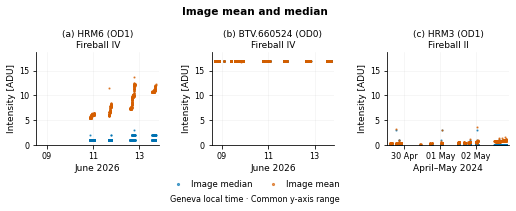

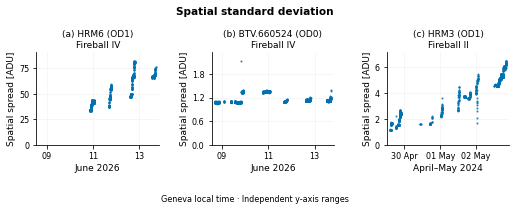

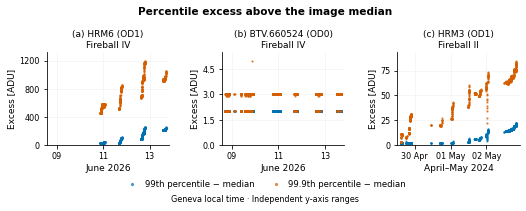

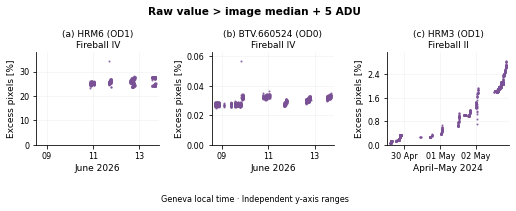

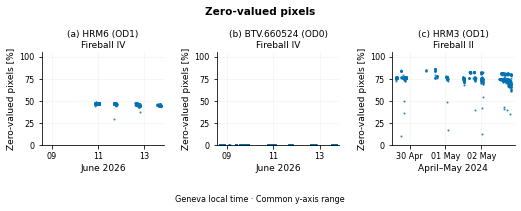

Saved the five additional combined PNGs to: /eos/home-i03/v/vtsoukni/SWAN_projects/MY HRMT64 image analysis/background_evolution_thesis_figures/combined_thesis
   combined_01_mean_median.png
   combined_02_spatial_std.png
   combined_03_percentile_excess.png
   combined_04_median_relative_fraction.png
   combined_05_zero_fraction.png


In [17]:
if "group_lookup" not in globals():
    raise RuntimeError(
        "Run the original imports, settings, definitions, and scan/inventory "
        "cells (Sections 1–3) first to build group_lookup."
    )

_thesis_combined_exports = make_combined_thesis_pngs(
    group_lookup,
    OUTPUT_DIR,
    layout=THESIS_COMBINED_LAYOUT,
    share_y=THESIS_COMBINED_SHARE_Y,
    group_selection=THESIS_COMBINED_GROUP_SELECTION,
    delta_adu=EXCESS_DELTA_ADU,
    timezone=LOCAL_TIMEZONE,
    dpi=THESIS_COMBINED_DPI,
    save=THESIS_COMBINED_SAVE,
    show=THESIS_COMBINED_SHOW,
)


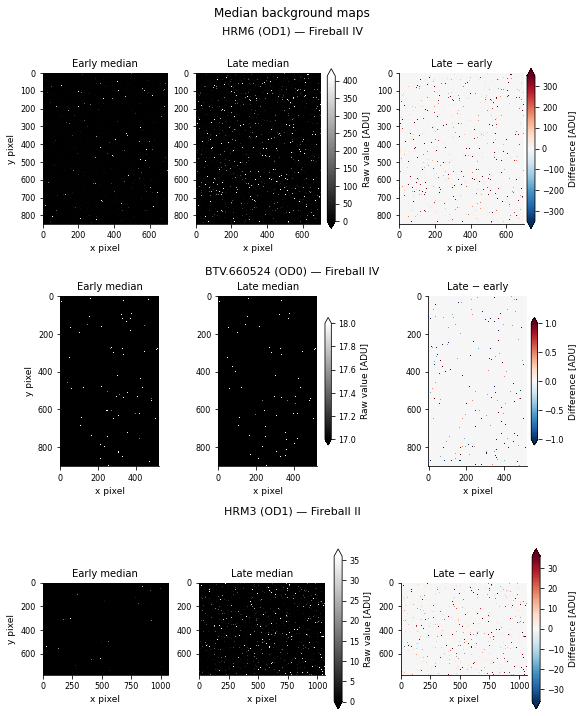

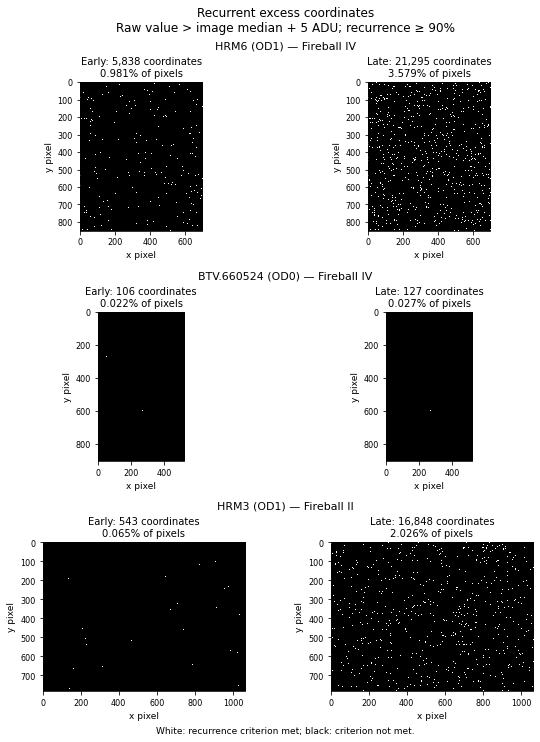

Saved: /eos/home-i03/v/vtsoukni/SWAN_projects/MY HRMT64 image analysis/background_evolution_thesis_figures/combined_thesis/combined_median_background_maps.png
Saved: /eos/home-i03/v/vtsoukni/SWAN_projects/MY HRMT64 image analysis/background_evolution_thesis_figures/combined_thesis/combined_recurrence_maps.png


In [18]:
# Run after the cell that builds epoch_data and epoch_summary.
# Saves both PNGs regardless of the original SAVE_RESULTS setting.

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt


def save_combined_background_maps():
    if "epoch_data" not in globals() or "group_lookup" not in globals():
        raise RuntimeError("Run the original early/late sample calculation first.")

    selected = []
    for case_key, camera in [
        ("HRM6_OD1", "HRM6"),
        ("BTV_660524_OD0", "BTV.660524"),
        ("HRM3_OD1", "HRM3"),
    ]:
        matches = [
            g for g in group_lookup
            if group_lookup[g]["case"]["key"] == case_key and g in epoch_data
        ]
        if len(matches) != 1:
            raise ValueError(
                f"Expected one early/late group for {case_key}; found {matches}."
            )

        group = matches[0]
        case = group_lookup[group]["case"]
        label = f"{camera} ({case['filter']}) — {case['campaign']}"
        selected.append((group, label))

    folder = Path(OUTPUT_DIR) / "combined_thesis"
    folder.mkdir(parents=True, exist_ok=True)
    dpi = 400
    paths = []

    with plt.rc_context({
        "font.size": 10,
        "axes.titlesize": 10,
        "axes.labelsize": 9,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
    }):
        # ------------------------------------------------------------
        # Median maps: one dataset per row; early, late, difference.
        # ------------------------------------------------------------
        fig = plt.figure(figsize=(8.0, 10.2), constrained_layout=True)
        fig.suptitle("Median background maps", fontsize=12)

        for row, (group, label) in zip(fig.subfigures(3, 1), selected):
            row.suptitle(label, fontsize=11)
            axes = row.subplots(1, 3)

            early = np.asarray(
                epoch_data[group]["early"]["median_image"], dtype=float
            )
            late = np.asarray(
                epoch_data[group]["late"]["median_image"], dtype=float
            )
            difference = late - early

            # Same limits as the original maps:
            # early/late share a scale within each dataset.
            # Different datasets have independent colour scales.
            vmin = min(np.percentile(early, 1), np.percentile(late, 1))
            vmax = max(
                np.percentile(early, MAP_DISPLAY_PERCENTILE),
                np.percentile(late, MAP_DISPLAY_PERCENTILE),
                vmin + 1,
            )
            limit = max(
                np.percentile(np.abs(difference), MAP_DISPLAY_PERCENTILE), 1
            )

            raw_image = axes[0].imshow(
                early, cmap="gray", vmin=vmin, vmax=vmax,
                origin="upper", interpolation="nearest",
            )
            axes[1].imshow(
                late, cmap="gray", vmin=vmin, vmax=vmax,
                origin="upper", interpolation="nearest",
            )
            diff_image = axes[2].imshow(
                difference, cmap="RdBu_r", vmin=-limit, vmax=limit,
                origin="upper", interpolation="nearest",
            )

            for ax, title in zip(
                axes, ["Early median", "Late median", "Late − early"]
            ):
                ax.set(title=title, xlabel="x pixel")
            axes[0].set_ylabel("y pixel")

            row.colorbar(
                raw_image, ax=axes[:2].tolist(),
                label="Raw value [ADU]",
                shrink=0.75, extend="both", pad=0.025,
            )
            row.colorbar(
                diff_image, ax=axes[2],
                label="Difference [ADU]",
                shrink=0.75, extend="both", pad=0.025,
            )

        path = folder / "combined_median_background_maps.png"
        fig.savefig(
            path, dpi=dpi, bbox_inches="tight",
            facecolor="white", transparent=False,
        )
        paths.append(path)
        plt.show()
        plt.close(fig)

        # ------------------------------------------------------------
        # Recurrence masks: one dataset per row; early and late.
        # White coordinates satisfy the original recurrence criterion.
        # ------------------------------------------------------------
        fig = plt.figure(figsize=(8.0, 10.2), constrained_layout=True)
        fig.suptitle(
            "Recurrent excess coordinates\n"
            f"Raw value > image median + {EXCESS_DELTA_ADU:g} ADU; "
            f"recurrence ≥ {100 * PERSISTENCE_FRACTION:g}%",
            fontsize=12,
        )

        for row, (group, label) in zip(fig.subfigures(3, 1), selected):
            row.suptitle(label, fontsize=11)
            axes = row.subplots(1, 2)

            for ax, name in zip(axes, ["early", "late"]):
                mask = np.asarray(
                    epoch_data[group][name]["persistent_mask"], dtype=bool
                )
                ax.imshow(
                    mask, cmap="gray", vmin=0, vmax=1,
                    origin="upper", interpolation="nearest",
                )
                ax.set_title(
                    f"{name.capitalize()}: {int(mask.sum()):,} coordinates\n"
                    f"{100 * mask.mean():.3f}% of pixels"
                )
                ax.set(xlabel="x pixel", ylabel="y pixel")

        fig.supxlabel(
            "White: recurrence criterion met; black: criterion not met.",
            fontsize=9,
        )

        path = folder / "combined_recurrence_maps.png"
        fig.savefig(
            path, dpi=dpi, bbox_inches="tight",
            facecolor="white", transparent=False,
        )
        paths.append(path)
        plt.show()
        plt.close(fig)

    for path in paths:
        print("Saved:", path.resolve())


save_combined_background_maps()